In [5]:
import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt
data=pd.read_csv("stores_sales_forecasting.csv", encoding="latin-1")

In [6]:
data

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2116,9963,CA-2015-168088,3/19/2015,3/22/2015,First Class,CM-12655,Corinna Mitchell,Home Office,United States,Houston,...,77041,Central,FUR-BO-10004218,Furniture,Bookcases,Bush Heritage Pine Collection 5-Shelf Bookcase...,383.4656,4,0.32,-67.6704
2117,9965,CA-2016-146374,12/5/2016,12/10/2016,Second Class,HE-14800,Harold Engle,Corporate,United States,Newark,...,19711,East,FUR-FU-10002671,Furniture,Furnishings,Electrix 20W Halogen Replacement Bulb for Zoom...,13.4000,1,0.00,6.4320
2118,9981,US-2015-151435,9/6/2015,9/9/2015,Second Class,SW-20455,Shaun Weien,Consumer,United States,Lafayette,...,70506,South,FUR-TA-10001039,Furniture,Tables,KI Adjustable-Height Table,85.9800,1,0.00,22.3548
2119,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028


In [7]:
data.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [15]:
data.isnull().sum()
data.isnull()
data.duplicated()
data.shape
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         2121 non-null   int64  
 1   Order ID       2121 non-null   str    
 2   Order Date     2121 non-null   str    
 3   Ship Date      2121 non-null   str    
 4   Ship Mode      2121 non-null   str    
 5   Customer ID    2121 non-null   str    
 6   Customer Name  2121 non-null   str    
 7   Segment        2121 non-null   str    
 8   Country        2121 non-null   str    
 9   City           2121 non-null   str    
 10  State          2121 non-null   str    
 11  Postal Code    2121 non-null   int64  
 12  Region         2121 non-null   str    
 13  Product ID     2121 non-null   str    
 14  Category       2121 non-null   str    
 15  Sub-Category   2121 non-null   str    
 16  Product Name   2121 non-null   str    
 17  Sales          2121 non-null   float64
 18  Quantity       2121

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000
mean,5041.643564,55726.556341,349.834887,3.785007,0.173923,8.699327
std,2885.740258,32261.888225,503.179145,2.251620,0.181547,136.049246
min,1.000000,1040.000000,1.892000,1.000000,0.000000,-1862.312400
25%,2568.000000,22801.000000,47.040000,2.000000,0.000000,-12.849000
50%,5145.000000,60505.000000,182.220000,3.000000,0.200000,7.774800
75%,7534.000000,90032.000000,435.168000,5.000000,0.300000,33.726600
max,9991.000000,99301.000000,4416.174000,14.000000,0.700000,1013.127000


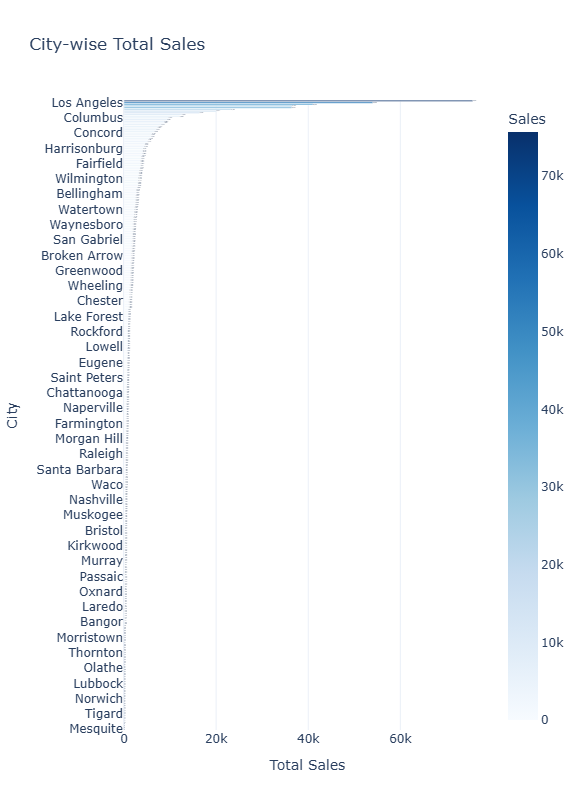

In [26]:
# minmum city are sales
import plotly.express as px

graph = data.groupby("City")["Sales"].sum().sort_values(ascending=True).reset_index()

fig = px.bar(
    graph,
    x="Sales",
    y="City",
    orientation="h",
    title="City-wise Total Sales",
    color="Sales",
    color_continuous_scale="Blues",
    text="Sales"
)

fig.update_layout(
    width=1000,
    height=800,
    xaxis_title="Total Sales",
    yaxis_title="City",
    yaxis=dict(automargin=True),
    template="plotly_white"
)

fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

fig.show()


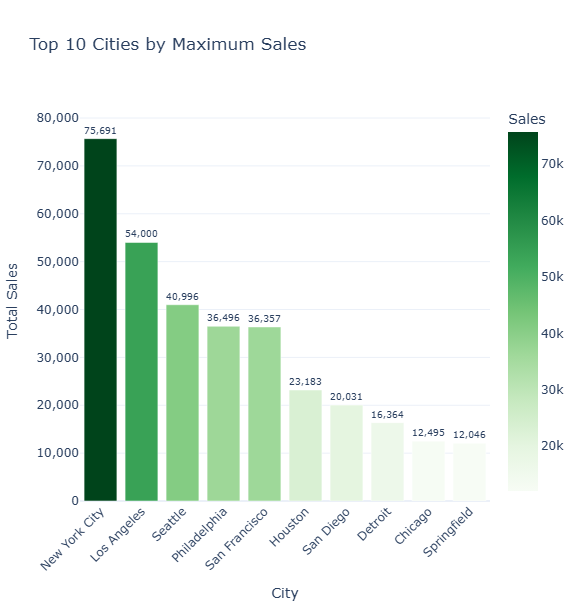

In [27]:
#top 10 max sales
import plotly.express as px

# City-wise total sales
graph = (
    data.groupby("City")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

fig = px.bar(
    graph,
    x="City",
    y="Sales",
    title="Top 10 Cities by Maximum Sales",
    color="Sales",
    color_continuous_scale="Greens",
    text="Sales"
)

fig.update_layout(
    width=1000,
    height=600,
    template="plotly_white",
    xaxis_title="City",
    yaxis_title="Total Sales",
    xaxis_tickangle=-45,
    yaxis_tickformat=",d"
)

fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

fig.show()


In [28]:
data

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2116,9963,CA-2015-168088,3/19/2015,3/22/2015,First Class,CM-12655,Corinna Mitchell,Home Office,United States,Houston,...,77041,Central,FUR-BO-10004218,Furniture,Bookcases,Bush Heritage Pine Collection 5-Shelf Bookcase...,383.4656,4,0.32,-67.6704
2117,9965,CA-2016-146374,12/5/2016,12/10/2016,Second Class,HE-14800,Harold Engle,Corporate,United States,Newark,...,19711,East,FUR-FU-10002671,Furniture,Furnishings,Electrix 20W Halogen Replacement Bulb for Zoom...,13.4000,1,0.00,6.4320
2118,9981,US-2015-151435,9/6/2015,9/9/2015,Second Class,SW-20455,Shaun Weien,Consumer,United States,Lafayette,...,70506,South,FUR-TA-10001039,Furniture,Tables,KI Adjustable-Height Table,85.9800,1,0.00,22.3548
2119,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028


In [30]:
data.groupby("Category")["Sales"].sum()

Category
Furniture    741999.7953
Name: Sales, dtype: float64

In [36]:
#which product high sales 
sub=data.groupby("Sub-Category")["Sales"].sum()
sub

Sub-Category
Bookcases      114879.9963
Chairs         328449.1030
Furnishings     91705.1640
Tables         206965.5320
Name: Sales, dtype: float64

In [41]:
order_datesales=data.groupby("Order ID")["Sales"].max()
order_datesales

Order ID
CA-2014-100090    502.488
CA-2014-100678    317.058
CA-2014-100706     29.460
CA-2014-100916    591.320
CA-2014-101462     59.920
                   ...   
US-2017-167318    362.352
US-2017-167402    212.940
US-2017-167570    215.544
US-2017-168613    145.764
US-2017-169551     87.210
Name: Sales, Length: 1764, dtype: float64

In [49]:
#machine learning model create feature engeerings prediction start are you code....
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def split_features_target(data,target_column="Profit"):#feature are set
    X = data.drop(target_column, axis=1)
    y = data[target_column]
    return X, y
# 2. Preprocessor are  function
def build_preprocessor(numeric_features, categorical_features):
# Numerical pipeline: missing values fill + scaling
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical pipeline: missing values fill + One-Hot Encoding
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])
    return preprocessor
# 3. build ML Pipeline is function
def build_model(preprocessor):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            max_depth=15
        ))
    ])
    return model
# 4. Model are train is  function
def train_model(model, X_train, y_train):
    model.fit(X_train, y_train)
    print("model are complete!")
    return model
# 5. Model on performance check is function
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)
    print("\nMAE:",mae)
    print("RMSE:",rmse)
    print("R2 Score:",r2)
    
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

X, y = split_features_target(data)

numeric_features=[
    "Sales",
    "Quantity",
    "Discount"
]
categorical_features = [
    "Ship Mode",
    "Segment",
    "Country",
    "City",
    "Region",
    "Category",
    "Sub-Category"
]

preprocessor = build_preprocessor(numeric_features, categorical_features)
model = build_model(preprocessor)

# 80% training && 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = train_model(model, X_train, y_train)
evaluate_model(model, X_test, y_test)
# 7. new data insert 


newdata = pd.DataFrame({
    "Sales": [500],
    "Quantity": [2],
    "Discount": [0.10],
    "Ship Mode": ["Second Class"],
    "Segment": ["Consumer"],
    "Country": ["United States"],
    "City": ["New York"],
    "Region": ["East"],
    "Category": ["Furniture"],
    "Sub-Category": ["Bookcases"]
})

# Prediction
prediction = model.predict(newdata)[0]

print(f"Predicted Profit: {prediction:,.2f}")


model are complete!

MAE: 24.490640958153065
RMSE: 53.723995876926175
R2 Score: 0.8386482364910285
Predicted Profit: 99.42


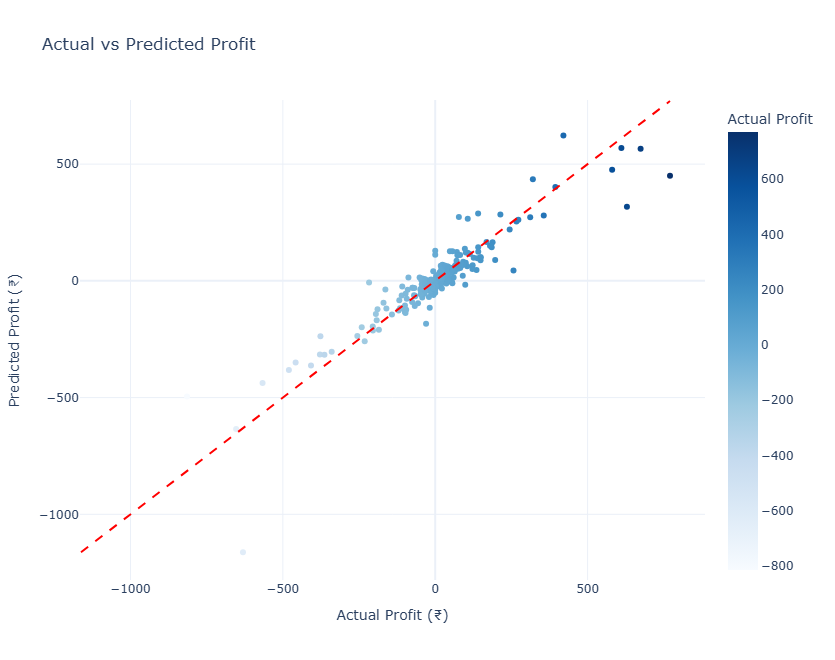

In [50]:

import plotly.express as px
import pandas as pd

# Actual and Predicted values
y_pred = model.predict(X_test)

graph = pd.DataFrame({
    "Actual Profit": y_test.values,
    "Predicted Profit": y_pred
})

# Graph
fig = px.scatter(
    graph,
    x="Actual Profit",
    y="Predicted Profit",
    title="Actual vs Predicted Profit",
    color="Actual Profit",
    color_continuous_scale="Blues",
    hover_data=["Predicted Profit"]
)

# Perfect prediction reference line
min_value = min(graph["Actual Profit"].min(),
                graph["Predicted Profit"].min())

max_value = max(graph["Actual Profit"].max(),
                graph["Predicted Profit"].max())

fig.add_shape(
    type="line",
    x0=min_value,
    y0=min_value,
    x1=max_value,
    y1=max_value,
    line=dict(color="red", dash="dash", width=2)
)

fig.update_layout(
    template="plotly_white",
    width=1000,
    height=650,
    xaxis_title="Actual Profit (₹)",
    yaxis_title="Predicted Profit (₹)"
)

fig.show()
